In [45]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import fetch_openml

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error as MSE

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.feature_selection import RFE
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectFromModel

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler;
from sklearn.preprocessing import RobustScaler;

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR
from sklearn.tree import plot_tree

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import BorderlineSMOTE

from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import NearMiss
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours


from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

#1  Загрузите предложенный вам датасет с помощью функции sklearn.datasets.fetch_openml. Выведите текстовое описание загруженного датасета.

In [8]:
data = fetch_openml('analcatdata_negotiation',as_frame=True)
x = data.data
y = data.target
df = data.frame
print(data.DESCR)

**Author**:   
**Source**: Unknown - Date unknown  
**Please cite**:   

analcatdata    A collection of data sets used in the book "Analyzing Categorical Data,"
by Jeffrey S. Simonoff, Springer-Verlag, New York, 2003. The submission
consists of a zip file containing two versions of each of 84 data sets,
plus this README file. Each data set is given in comma-delimited ASCII
(.csv) form, and Microsoft Excel (.xls) form.

NOTICE: These data sets may be used freely for scientific, educational and/or
noncommercial purposes, provided suitable acknowledgment is given (by citing
the above-named reference).

Further details concerning the book, including information on statistical software
(including sample S-PLUS/R and SAS code), are available at the web site

http://www.stern.nyu.edu/~jsimonof/AnalCatData


Information about the dataset
CLASSTYPE: numeric
CLASSINDEX: last


Note: Quotes, Single-Quotes and Backslashes were removed, Blanks replaced
with Underscores

Downloaded from openml.org.


#2 Проверьте структуру данных: количество строк и столбцов, типы признаков, наличие пропущенных значений.

In [12]:
display(df.describe())
display(df.info())
display(df.head())
print(f'\n\n\n')
print(f'Количество пропущенных значений: ')
print(df.isnull().sum())

,Status,Trust,Outcome_favorability,Procedural_fairness,Future_business
count,78.000000,83.000000,90.000000,91.000000,92.000000
mean,62.844255,49.311532,53.544974,64.416536,5.934783
std,11.159715,15.800148,15.447846,15.574020,1.127131
min,32.407407,7.142857,14.285714,14.285714,2.000000
25%,55.555556,40.476190,42.857143,52.380952,5.000000
50%,63.425926,50.000000,52.380952,66.666667,6.000000
75%,71.296296,59.523810,66.666667,76.190476,7.000000
max,84.259259,80.952381,85.714286,85.714286,7.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   Role                  92 non-null     category
 1   Status                78 non-null     float64 
 2   Trust                 83 non-null     float64 
 3   Outcome_favorability  90 non-null     float64 
 4   Procedural_fairness   91 non-null     float64 
 5   Future_business       92 non-null     int64   
dtypes: category(1), float64(4), int64(1)
memory usage: 3.9 KB


None

,Role,Status,Trust,Outcome_favorability,Procedural_fairness,Future_business
0,Recruiter,66.666667,64.285714,38.095238,57.142857,6
1,Recruiter,71.296296,57.142857,47.619048,80.952381,6
2,Candidate,NaN,NaN,71.428571,71.428571,6
3,Candidate,67.592593,45.238095,57.142857,71.428571,6
4,Recruiter,32.407407,52.380952,71.428571,85.714286,7






Количество пропущенных значений: 
Role                     0
Status                  14
Trust                    9
Outcome_favorability     2
Procedural_fairness      1
Future_business          0
dtype: int64


#3. Визуализация данных

Постройте гистограммы для числовых признаков.



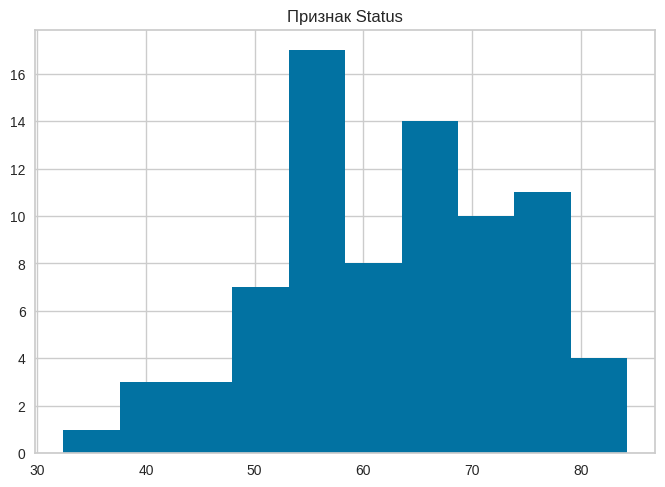

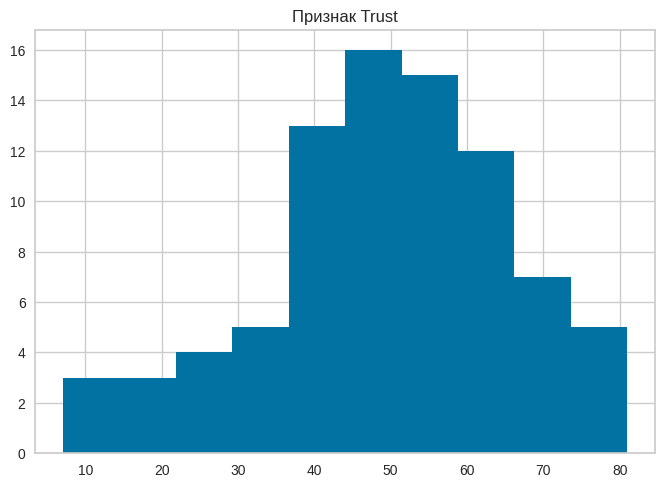

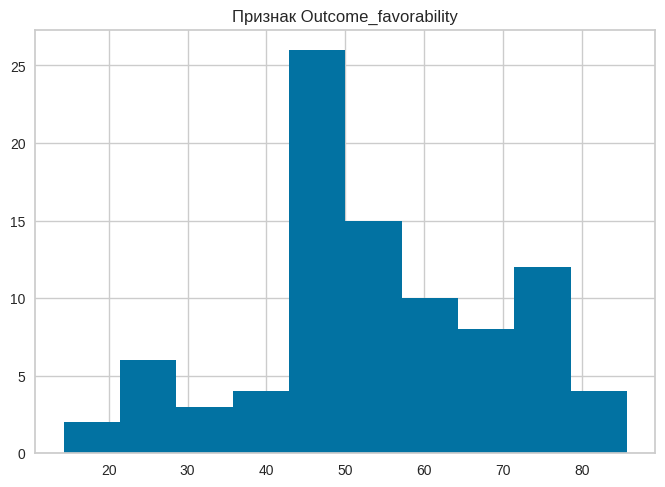

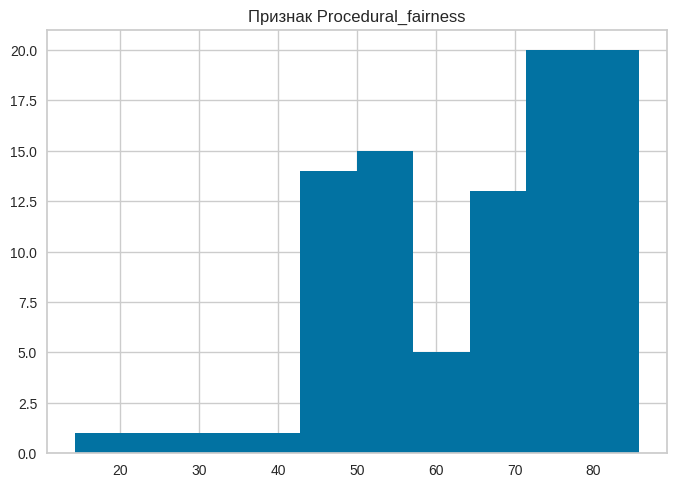

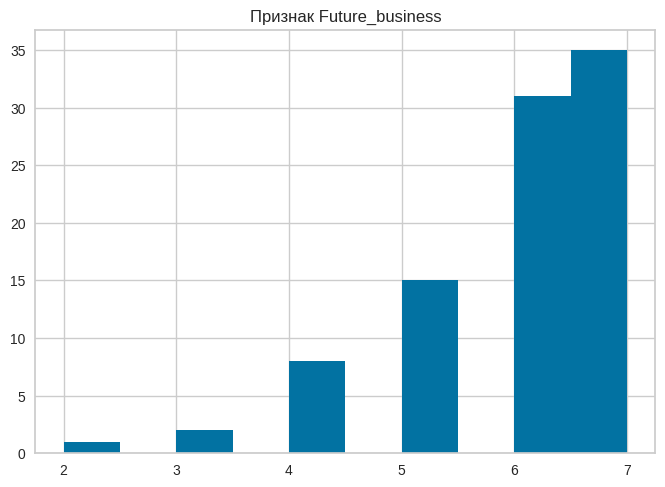



Для категориальных признаков постройте столбчатые диаграммы.



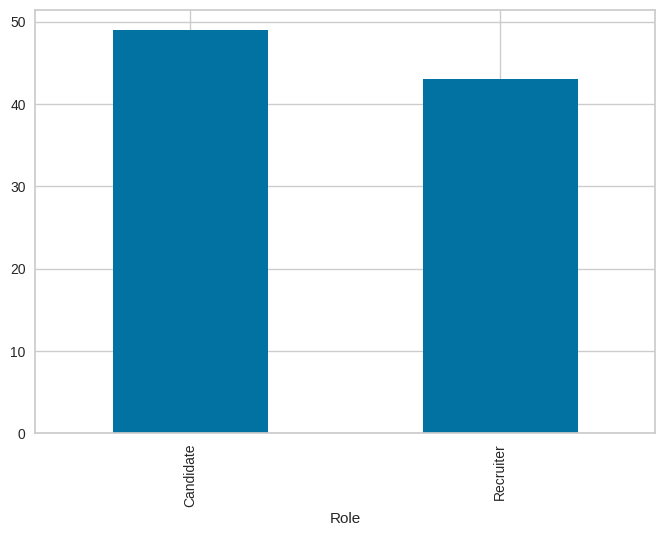



Постройте графики связи атрибутов с целевой переменной



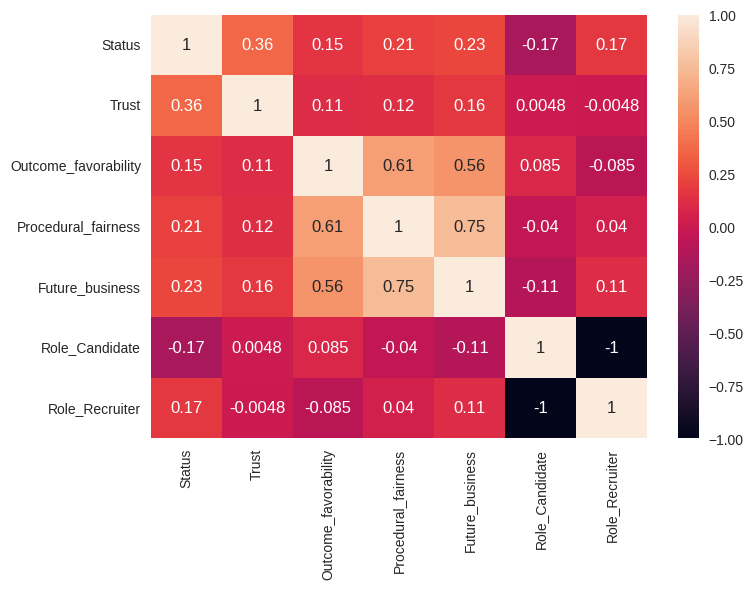



Исследуйте распределение целевой переменной.



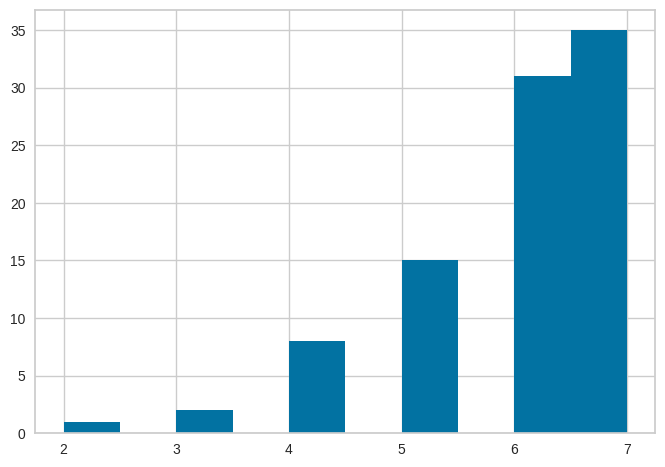



Проведите анализ выбросов.



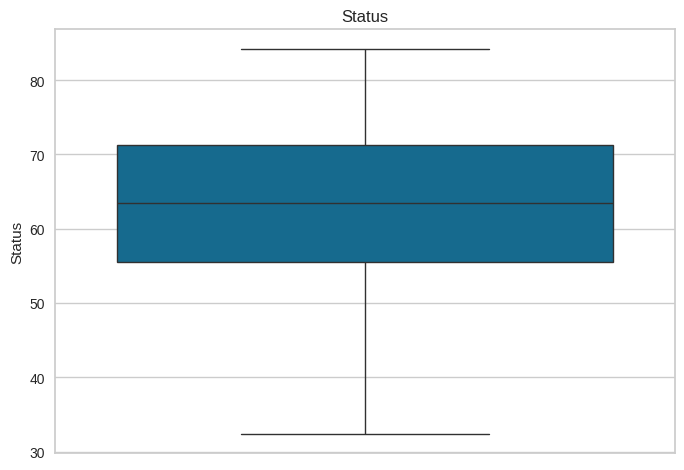

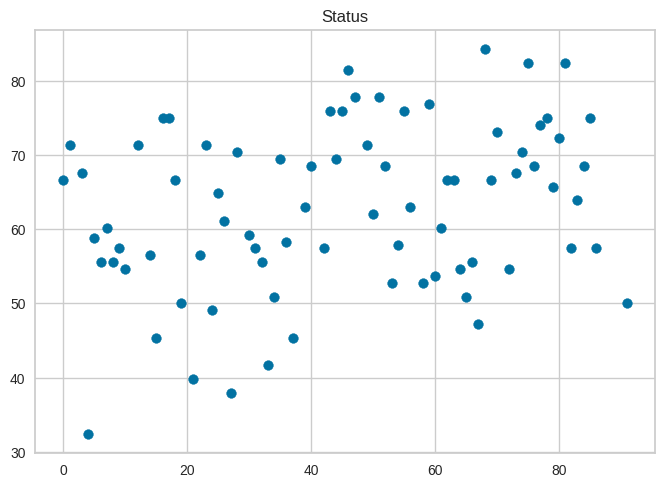

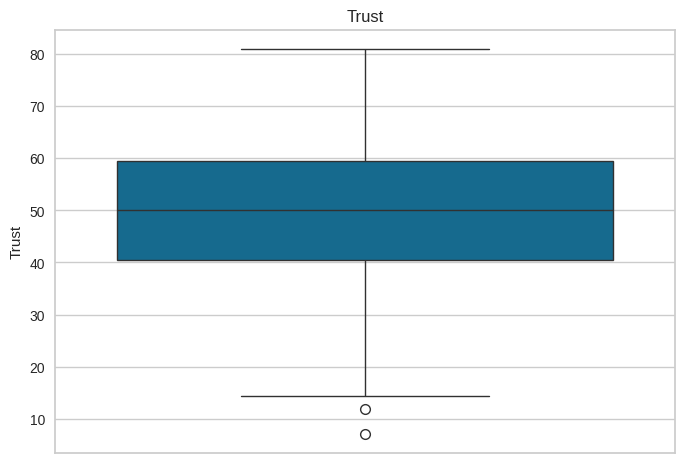

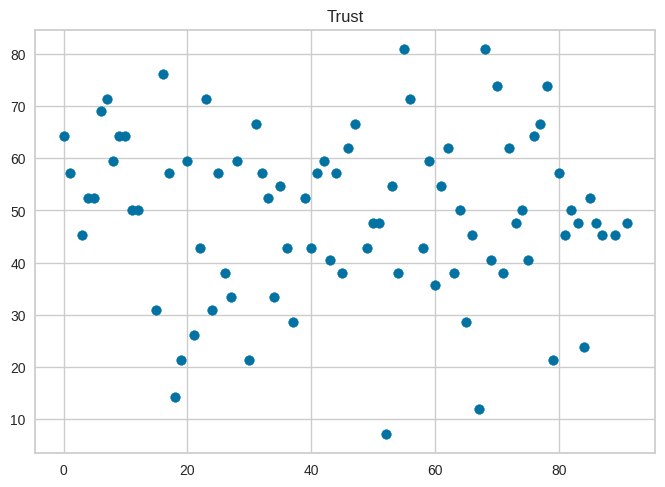

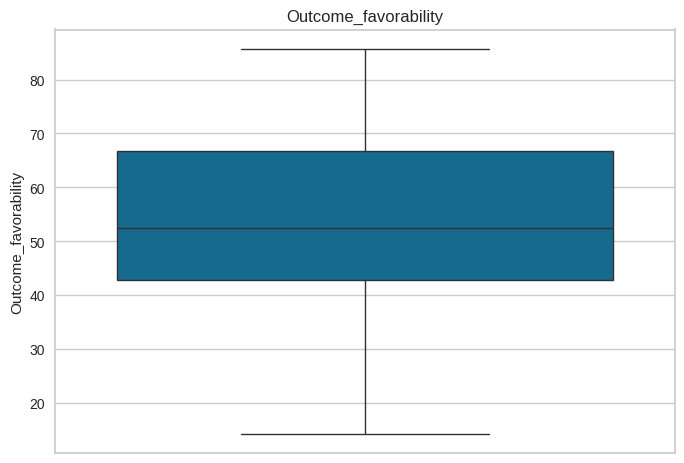

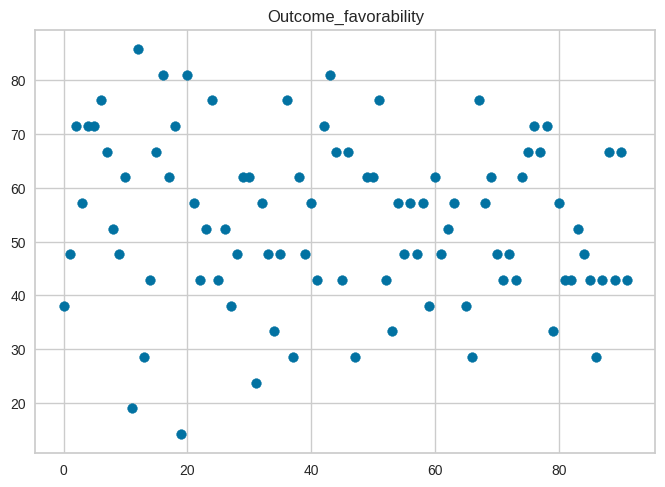

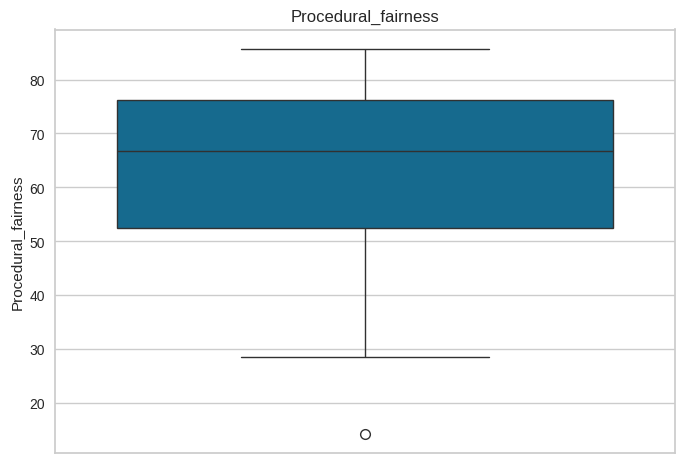

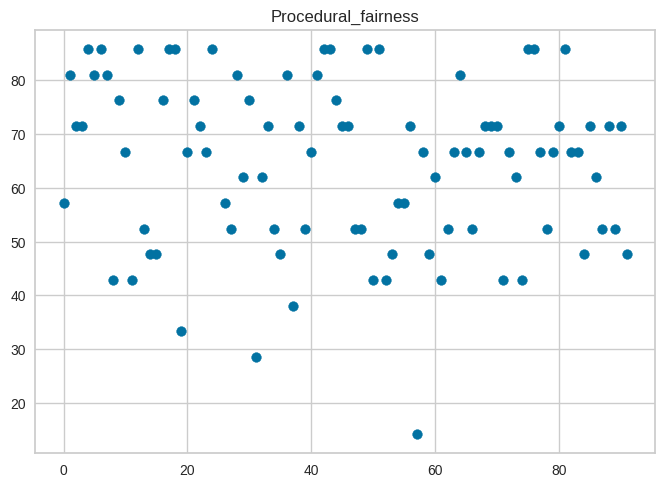

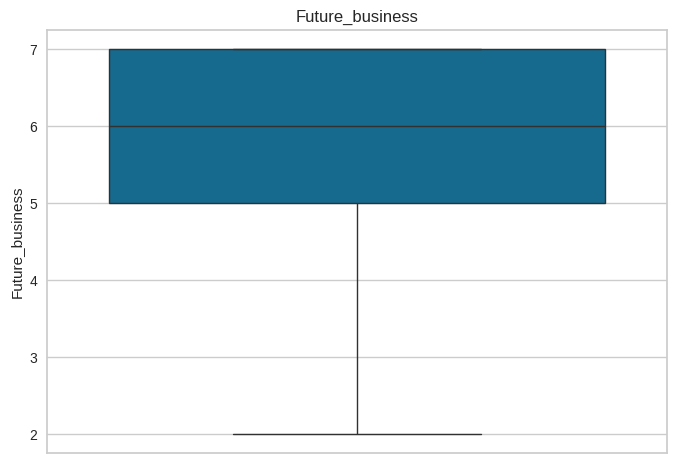

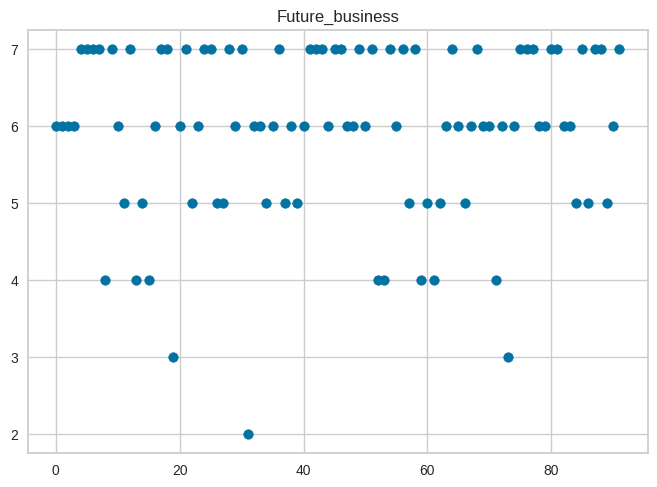

In [25]:
print(f'Постройте гистограммы для числовых признаков.\n')
#Постройте гистограммы для числовых признаков.
for i in df.select_dtypes(include=['int64', 'float64']).columns:
  plt.hist(df[[i]]);plt.title(f'Признак {i}');plt.show()

#Для категориальных признаков постройте столбчатые диаграммы.
print(f'\n\nДля категориальных признаков постройте столбчатые диаграммы.\n')
for i in df.select_dtypes(include=['object', 'category']).columns:
  df[i].value_counts().plot(kind='bar');plt.show()

#Постройте графики связи атрибутов с целевой переменной
print(f'\n\nПостройте графики связи атрибутов с целевой переменной\n')
sns.heatmap(pd.get_dummies(df).corr(),annot=True);plt.show()

#Исследуйте распределение целевой переменной.
print(f'\n\nИсследуйте распределение целевой переменной.\n')
plt.hist(y);plt.show()

#Проведите анализ выбросов.
print(f'\n\nПроведите анализ выбросов.\n')
for i in df.select_dtypes(include=['int64', 'float64']).columns:
  sns.boxplot(df[i]);plt.title(i);plt.show()
  plt.scatter(np.arange(len(df[i])),df[i]);plt.title(i);plt.show()


#4 Предобработка данных (выберите 2-3 варианта на свое усмотрение)


Бинаризация признака.



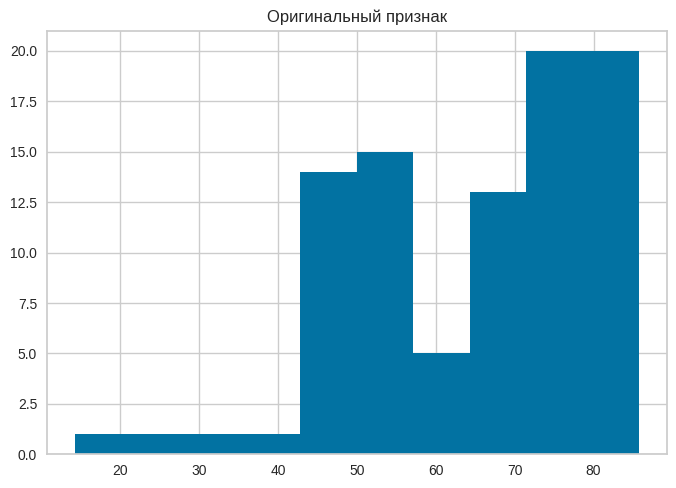

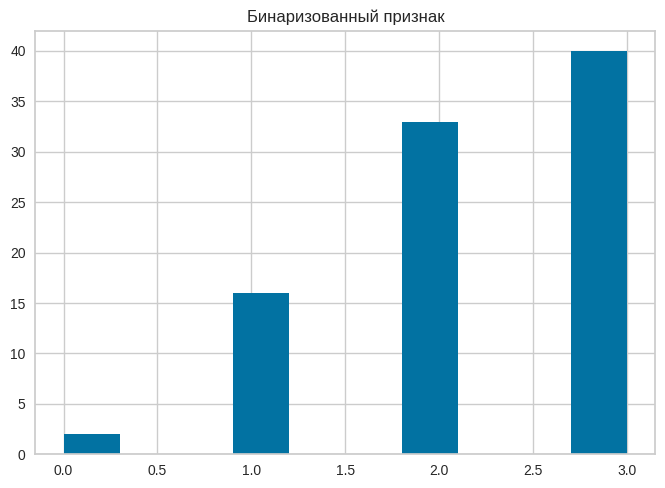



Нормализация данных (MinMax, StandardScaler, RobustScaler).



,Status,Trust,Outcome_favorability,Procedural_fairness
count,75.000000,75.000000,75.000000,75.000000
mean,63.012346,49.206349,54.095238,65.714286
std,11.315831,16.474035,15.213139,14.997293
min,32.407407,7.142857,14.285714,28.571429
25%,55.555556,39.285714,42.857143,52.380952
50%,63.888889,50.000000,57.142857,66.666667
75%,71.296296,60.714286,66.666667,76.190476
max,84.259259,80.952381,85.714286,85.714286




StandardScaler



,Status,Trust,Outcome_favorability,Procedural_fairness
count,7.500000e+01,7.500000e+01,7.500000e+01,7.500000e+01
mean,3.523108e-16,-1.076916e-16,2.753353e-16,-3.523108e-16
std,1.006734e+00,1.006734e+00,1.006734e+00,1.006734e+00
min,-2.722826e+00,-2.570515e+00,-2.634407e+00,-2.493315e+00
25%,-6.634073e-01,-6.062535e-01,-7.436843e-01,-8.950363e-01
50%,7.798331e-02,4.850028e-02,2.016771e-01,6.393116e-02
75%,7.369972e-01,7.032540e-01,8.319181e-01,7.032428e-01
max,1.890271e+00,1.940011e+00,2.092400e+00,1.342554e+00




MinMax



...

,Status,Trust,Outcome_favorability,Procedural_fairness
count,75.000000,75.000000,75.000000,75.000000
mean,63.012346,49.206349,54.095238,65.714286
std,11.315831,16.474035,15.213139,14.997293
min,32.407407,7.142857,14.285714,28.571429
25%,55.555556,39.285714,42.857143,52.380952
50%,63.888889,50.000000,57.142857,66.666667
75%,71.296296,60.714286,66.666667,76.190476
max,84.259259,80.952381,85.714286,85.714286


Index(['Role'], dtype='object')


One-hot


,Status,Trust,Outcome_favorability,Procedural_fairness,Role_Recruiter
0,66.666667,64.285714,38.095238,57.142857,True
1,71.296296,57.142857,47.619048,80.952381,True
3,67.592593,45.238095,57.142857,71.428571,False
4,32.407407,52.380952,71.428571,85.714286,True
5,58.796296,52.380952,71.428571,80.952381,True




Label encoder:



,0
0,1
1,1
2,0
3,1
4,1


In [54]:
#Бинаризация признака.
print(f'Бинаризация признака.\n')
#Возьмем признак с явными категориями - Procedural_fairness. У него много значений в диапазонах от ~42 до ~57 и от ~65 до ~85
enc = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='kmeans')
binned = enc.fit_transform(df['Procedural_fairness'].dropna().values.reshape(-1, 1)).flatten()
plt.hist(df['Procedural_fairness'].dropna());plt.title('Оригинальный признак');plt.show()
plt.hist(binned);plt.title('Бинаризованный признак');plt.show()

#Нормализация данных (MinMax, StandardScaler, RobustScaler).
print(f'\n\nНормализация данных (MinMax, StandardScaler, RobustScaler).\n')
df_processed = df.dropna().drop('Future_business',axis=1)
display(df_processed.describe())
num_cols=df_processed.select_dtypes(include=['float64','int64']).columns
print(f'\n\nStandardScaler\n')
scaler = SC()
df_processed[num_cols] = scaler.fit_transform(df_processed[num_cols])
display(df_processed.describe())
print(f'\n\nMinMax\n')
df_processed = df.dropna().drop('Future_business',axis=1)
scaler = MinMaxScaler()
df_processed[num_cols] = scaler.fit_transform(df_processed[num_cols])
display(df_processed.describe())
print(f'\n\nRobust\n')
df_processed = df.dropna().drop('Future_business',axis=1)
scaler = RobustScaler()
df_processed[num_cols] = scaler.fit_transform(df_processed[num_cols])
display(df_processed.describe())

#Преобразование категориальных признаков (One-Hot Encoding, Label Encoding).
print(f'\n\nПреобразование категориальных признаков (One-Hot Encoding, Label Encoding).\n')
df_processed = df.dropna().drop('Future_business',axis=1)
display(df_processed.describe())
cat_cols=df_processed.select_dtypes(include=['object', 'category']).columns
print(cat_cols)
#One-Hot:
print(f'\n\nOne-hot')
one_hotted=pd.get_dummies(df_processed, columns=cat_cols, drop_first=True)
display(one_hotted.head())
#Label Encoder:
print(f'\n\nLabel encoder:\n')
label_encoder = LabelEncoder()
encoded = pd.DataFrame(label_encoder.fit_transform(df_processed[cat_cols]))
display(encoded.head())

#5. Обучение модели и оценка эффекта предобработки

In [59]:
# Разделите данные на train/test.

df_ = df.copy().dropna()
x_init = df_.drop('Future_business',axis=1)
y_init = df_[['Future_business']]
x_train, x_test, y_train, y_test = train_test_split(x_init, y_init, test_size=0.15, random_state=42)
num_cols=x_init.select_dtypes(include=['float64','int64']).columns
cat_cols=x_init.select_dtypes(include=['object', 'category']).columns

print(f'До\n')
# Обучите модель (например, LinearRegression или RandomForest) на сырых данных.
ms = [LR(),RFC()]
for i in ms:
  i.fit(x_train.drop(cat_cols,axis=1),y_train);print(f'Качество модели {i}: {i.score(x_test.drop(cat_cols,axis=1),y_test)}')

print(f'\nПосле\n')
# Повторите обучение на предобработанных данных (выбранные методы из п.3).

#Применим StandardScaler, One-hot encoder, бинаризацию

scaler = SC()
x_init[num_cols] = scaler.fit_transform(x_init[num_cols])
x_init = pd.get_dummies(x_init, columns=cat_cols, drop_first=True)
enc = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='kmeans')
binned = enc.fit_transform(x_init['Procedural_fairness'].dropna().values.reshape(-1, 1)).flatten()

x_train, x_test, y_train, y_test = train_test_split(x_init, y_init, test_size=0.15, random_state=42)

ms = [LR(),RFC()]
for i in ms:
  i.fit(x_train,y_train);print(f'Качество модели {i}: {i.score(x_test,y_test)}')


# Сравните качество моделей.
'''
незначительное улучшение качества для лог регрессии, нет изменений случайного леса
'''

# Сделайте вывод: какие методы предобработки дали наилучший результат?
'''
самыми полезными преобразованиями были One-Hot encoder и StandardScaler,
потому что One-Hot сохрянет ифнормативность категориального признака
в отличе от Label Encoder или просто drop(категориальные)
StandardScaler важен для любой модели, потому что делает значения признаков не завсимыми от их масштаба
'''


До

Качество модели LogisticRegression(): 0.5833333333333334
Качество модели RandomForestClassifier(): 0.5833333333333334

После

Качество модели LogisticRegression(): 0.6666666666666666
Качество модели RandomForestClassifier(): 0.5833333333333334


#Итоговый вывод: какие методы предобработки оказались наиболее полезными?

самыми полезными преобразованиями были One-Hot encoder и StandardScaler,
потому что One-Hot сохрянет ифнормативность категориального признака
в отличе от Label Encoder или просто drop(категориальные)
StandardScaler важен для любой модели, потому что делает значения признаков не завсимыми от их масштаба